# 09 | Einzelne Lieferzeiten und die Unsicherheit einer Kennzahl

**Lernziele:** Mittelwert, Median und P90 unterscheiden; mit Zurücklegen
aus Beobachtungen ziehen; ein Intervall für eine Kennzahl interpretieren.
**Vorwissen:** Listen, Funktionen, Seed, Verteilung und Intervall aus 03-08.
**Zeit:** geführte Demo, danach zwei Aufgaben mit je 15 Minuten.
Zehn erfundene Lieferzeiten in Arbeitstagen dienen der Handrechnung,
nicht als ausreichende Datengrundlage für ein echtes Lieferversprechen.
Alle Basiszellen sind ausführbar. Eigene Antworten in neuen Zellen notieren.
Kursumgebung mit NumPy, SciPy und Matplotlib; keine Downloads.

In [1]:
from random import Random
import math
from statistics import mean, median

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import bootstrap

plt.rcParams.update({"font.size": 13})
lieferzeiten = [1, 2, 2, 3, 3, 4, 4, 5, 6, 12]


def pruefe_lieferzeiten(werte):
    if len(werte) < 2 or not all(math.isfinite(wert) and wert >= 0 for wert in werte):
        raise ValueError("Mindestens zwei endliche nichtnegative Lieferzeiten erforderlich")


def datenbericht(werte):
    pruefe_lieferzeiten(werte)
    return {
        "anzahl": len(werte),
        "mittelwert": mean(werte),
        "median": median(werte),
        "p90": float(np.quantile(werte, 0.9, method="inverted_cdf")),
    }


print(datenbericht(lieferzeiten))

{'anzahl': 10, 'mittelwert': 4.2, 'median': 3.5, 'p90': 6.0}


## 1. Drei Kennzahlen, drei Bedeutungen

Der Mittelwert teilt die Summe durch die Anzahl. Der Median ist bei zehn
sortierten Werten der Mittelwert des fünften und sechsten Wertes.
Für P90 verwenden wir wie in 08 das empirische Quantil: den kleinsten
beobachteten Wert, bis zu dem mindestens 90 Prozent der Beobachtungen liegen.
Bei zehn Werten ist das der neunte sortierte Wert. Andere Software kann
zwischen Werten interpolieren; deshalb die Konvention angeben.
Die Medianregel bei gerader Anzahl ist hier bewusst die übliche Mittelung
beider mittlerer Werte, nicht das untere empirische 50-Prozent-Quantil.

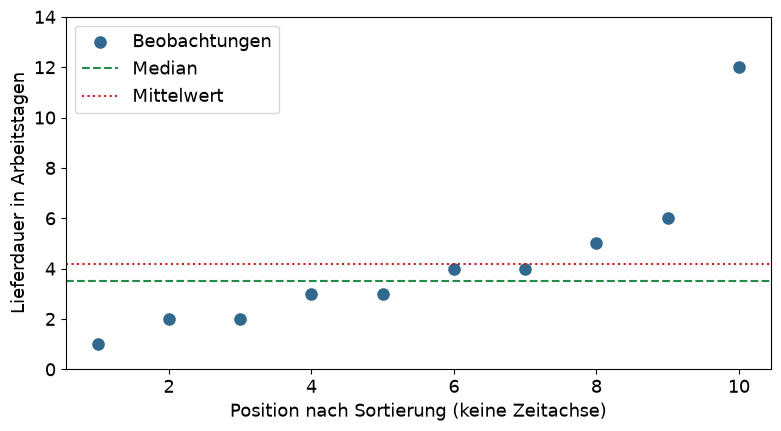

In [2]:
figur, achse = plt.subplots(figsize=(8, 4.5))
achse.scatter(range(1, 11), sorted(lieferzeiten), color="#31688e", s=65, label="Beobachtungen")
achse.axhline(median(lieferzeiten), color="#238b45", linestyle="--", label="Median")
achse.axhline(mean(lieferzeiten), color="#cb181d", linestyle=":", label="Mittelwert")
achse.set(xlabel="Position nach Sortierung (keine Zeitachse)", ylabel="Lieferdauer in Arbeitstagen", ylim=(0, 14))
achse.legend(loc="upper left")
figur.tight_layout()
plt.show()

## 2. Eine neue Stichprobe aus vorhandenen Beobachtungen

Wir tun für den Bootstrap so, als sei unsere beobachtete Stichprobe die
Ausgangsverteilung. Wir ziehen zehnmal **mit Zurücklegen** daraus.
Eine Beobachtung darf fehlen oder mehrfach vorkommen; die Stichprobengröße
bleibt zehn. Bei Python beginnt der erste Index bei 0.
Wir setzen unabhängige Lieferungen aus demselben Prozess voraus:
gleiche Verteilung bedeutet nicht, dass alle Dauern gleich häufig sind.
Mit **Population** meinen wir alle vergleichbaren Lieferungen, für die
diese Beobachtungen stehen sollen. Deren Median ist unbekannt; der Median
unserer zehn Daten ist dagegen direkt berechenbar.
Zuerst ein kleines, unabhängiges Beispiel ohne Zufall:

In [3]:
def resample_nach_indizes(werte, indizes):
    if len(werte) == 0 or len(indizes) != len(werte):
        raise ValueError("Ein Resample braucht ebenso viele Indizes wie Beobachtungen")
    if not all(isinstance(index, int) and 0 <= index < len(werte) for index in indizes):
        raise ValueError("Indizes muessen auf vorhandene Beobachtungen zeigen")
    return [werte[index] for index in indizes]


print(resample_nach_indizes([2, 5, 9], [2, 0, 2]))

[9, 2, 9]


## 3. Viele Resamples, pro Resample genau eine Kennzahl

**n = 10:** Zahl der beobachteten Lieferungen und Größe jedes Resamples.
**B = 2000:** Zahl der Resamples. Das sind keine 2000 neuen Lieferungen.
Wir speichern pro Resample nur den Median. Die mittleren 95 Prozent dieser
Mediane bilden hier das einfache **Perzentil-Bootstrap-Intervall**.
Dessen Grenzen werden mit linear interpolierten 2,5- und 97,5-Prozent-Quantilen
berechnet. Ein nominales 95-Prozent-Niveau garantiert bei zehn Beobachtungen
und diskreten Medianen keine tatsächliche 95-Prozent-Deckung.

In [4]:
def bootstrap_bericht(werte, wiederholungen, seed, kennzahl=median, konfidenz=0.95):
    pruefe_lieferzeiten(werte)
    if not isinstance(wiederholungen, int) or wiederholungen < 2:
        raise ValueError("Mindestens zwei ganze Bootstrap-Wiederholungen erforderlich")
    if not math.isfinite(konfidenz) or not 0 < konfidenz < 1:
        raise ValueError("Konfidenzniveau muss zwischen null und eins liegen")
    generator = Random(seed)
    schaetzwerte = []
    for wiederholung in range(wiederholungen):
        resample = generator.choices(werte, k=len(werte))
        schaetzwerte.append(float(kennzahl(resample)))
    punktwert = float(kennzahl(werte))
    if not all(math.isfinite(wert) for wert in [punktwert, *schaetzwerte]):
        raise ValueError("Kennzahl muss endliche Werte liefern")
    randanteil = (1 - konfidenz) / 2
    unten, oben = np.quantile(schaetzwerte, [randanteil, 1 - randanteil], method="linear")
    return {
        "beobachtungen": len(werte),
        "wiederholungen": wiederholungen,
        "punktwert": punktwert,
        "unten": float(unten),
        "oben": float(oben),
        "schaetzwerte": schaetzwerte,
    }


medianbericht = bootstrap_bericht(lieferzeiten, 2000, 42)
print({name: wert for name, wert in medianbericht.items() if name != "schaetzwerte"})

{'beobachtungen': 10, 'wiederholungen': 2000, 'punktwert': 3.5, 'unten': 2.0, 'oben': 5.0}


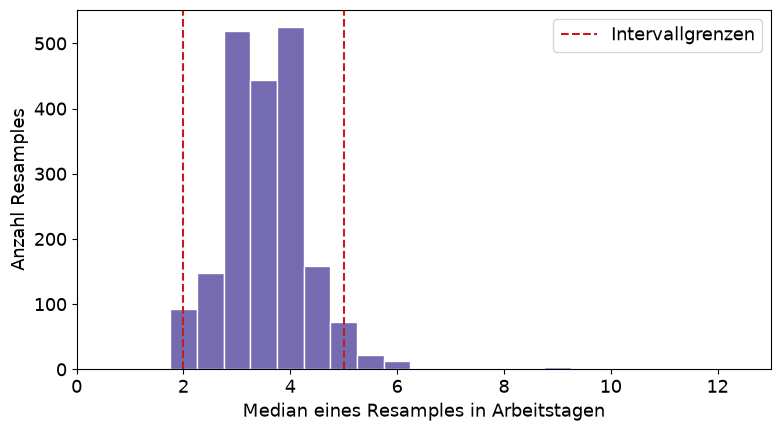

In [5]:
figur, achse = plt.subplots(figsize=(8, 4.5))
achse.hist(medianbericht["schaetzwerte"], bins=np.arange(0.75, 12.76, 0.5), color="#756bb1", edgecolor="white")
achse.axvline(medianbericht["unten"], color="#cb181d", linestyle="--", label="Intervallgrenzen")
achse.axvline(medianbericht["oben"], color="#cb181d", linestyle="--")
achse.set(xlabel="Median eines Resamples in Arbeitstagen", ylabel="Anzahl Resamples", xlim=(0, 13))
achse.legend()
figur.tight_layout()
plt.show()

**Die zwei Bilder zeigen verschiedene Dinge.** Im ersten steht ein Punkt
für eine beobachtete Lieferung. Im zweiten zählt ein Balken Mediane
vollständiger Resamples. Ein Intervall für den Populationsmedian
ist kein Vorhersageintervall für eine einzelne zukünftige Lieferung.

## A09.1 | Zwei Resamples von Hand | 15 Minuten

Verwenden Sie die zehn Lieferzeiten vom Anfang und die Indexfolgen
A = [0, 0, 1, 2, 3, 4, 5, 6, 7, 8] und
B = [1, 2, 3, 4, 5, 6, 7, 8, 9, 9]. Schreiben Sie beide Resamples auf,
bestimmen Sie ihre Mediane und markieren Sie fehlende/mehrfache Beobachtungen.
Prüfen Sie danach mit `resample_nach_indizes` und `median`.
Warum würde bloßes Mischen ohne Zurücklegen hier nicht funktionieren?
**Hilfe:** Indizes beginnen bei 0; bei zehn Werten liegen die mittleren
Einträge an den Positionen 5 und 6, also den Indizes 4 und 5.
CR09.1 kann den Programmierteil ersetzen, nicht die Interpretation.

## A09.2 | Kennzahl ändern, Ergebnis erklären | 15 Minuten

Rufen Sie `bootstrap_bericht(lieferzeiten, 2000, 42, kennzahl=mean)` auf.
Vergleichen Sie Punktwert und Intervall mit dem Medianbericht.
Schreiben Sie drei Sätze: "Geschätzt wird ...", "Das Intervall bezieht
sich auf ...", "Mehr Wiederholungen ändern nicht ...".
Warum folgt daraus kein Versprechen, dass 95 Prozent der Lieferungen
innerhalb dieser Intervallgrenzen ankommen?
**Hilfe:** Die Beobachtungen und n bleiben unverändert; nur die Kennzahl wechselt.
Die Definition von `bootstrap_bericht` nicht bearbeiten. In einer neuen
Codezelle den Aufruf unter `mittelbericht` speichern und gezielt ablesen:
```python
mittelbericht = bootstrap_bericht(lieferzeiten, 2000, 42, kennzahl=mean)
print(mittelbericht["punktwert"], mittelbericht["unten"], mittelbericht["oben"])
```
Die lange Liste `schaetzwerte` brauchen Sie für diese Tabelle nicht auszugeben.

## Pflichtteil endet hier

**Abschlussfrage:** Was kann größeres B verbessern, was nur bessere oder
zusätzliche Daten? Die folgenden Abschnitte sind Wahlteile.

## Wahlteil | Bibliotheksverfahren und ursprüngliches Beispiel

Das alte Kapitel nutzte 500 künstliche lognormale Lieferzeiten und 5000
Resamples. Wir behalten das Beispiel, kennzeichnen die Daten aber als
simuliert. Die Originalausgabe wird neu berechnet statt abgeschrieben.
SciPy verwendet hier ausdrücklich `method="percentile"`; sein Standard BCa
ist ein anderes Verfahren. `batch=100` begrenzt die gleichzeitig verarbeiteten
Resamples, nicht deren Gesamtzahl. Andere Generatoren liefern andere Ziehungen.

In [6]:
simulierte_dauern = np.random.default_rng(42).lognormal(mean=1.0, sigma=0.6, size=500)
scipy_bericht = bootstrap(
    (simulierte_dauern,), np.median, n_resamples=5000, confidence_level=0.95,
    method="percentile", batch=100, rng=np.random.default_rng(43),
)
print("Simulierter Median:", float(np.median(simulierte_dauern)))
print("Perzentil-Intervall:", tuple(float(grenze) for grenze in scipy_bericht.confidence_interval))

Simulierter Median: 2.7235299021063852
Perzentil-Intervall: (2.5126359069803175, 2.937135374729011)


## Wahlteil | Grenzen und andere Verfahren

Die einfache Methode setzt unabhängige, gleich verteilte und für die
Zielpopulation geeignete Beobachtungen voraus. Zeitreihen, gemeinsame
Störungen und Auswahlverzerrungen brauchen andere Modelle oder Designs.
Block-Bootstrap kann bestimmte Abhängigkeiten berücksichtigen, ist aber
kein universeller Ersatz für deren Analyse. BCa korrigiert unter geeigneten
Bedingungen Verzerrung und Asymmetrie; auch dieses Verfahren ist nicht immer
stabil, besonders bei kleinen, diskreten oder konstanten Daten.

"Bootstrap" bedeutet nicht automatisch "ausreißerrobust". Ein einzelner
großer Wert kann z.B. den Mittelwert und dessen Bootstrap-Verteilung stark
beeinflussen. Die Robustheit des Medians kommt nicht vom Resampling allein.
Hohe Quantile sind bei wenigen Beobachtungen besonders schlecht abgesichert.
Ein degeneriertes Intervall bei lauter gleichen Werten beweist keine
konstanten Dauern in der Grundgesamtheit. Mehr B heilt keines dieser Probleme.